# Entrega 2 — YOLO padrão e comparação das três abordagens

**Autor:** Elton Modesto de Souza Dias — RM 572530. **Grupo 21. Tutora:** Nicolly Candida.

**Integrantes:** Lucas Carvalho Cordeiro — RM 570388; Larissa da Silva Marcelino — RM 571790; Elton Modesto de Souza Dias — RM 572530; Matheus Fontes — RM 570457.

Nova execução na **base v2**, depois de substituir quatro fotografias repetidas. A YOLOv5s padrão foi pré-treinada no COCO e não é treinada nas 80 fotos do grupo. `banana` é a classe COCO 46 e `bottle` é a classe 39, usada como aproximação de garrafa PET. A versão é a adotada na contribuição original; o material do capítulo 3 não foi disponibilizado para verificar uma variante específica.

As células executam a inferência e geram caixas previstas, galeria, comparação por foto e condições dos tempos. Dados antigos ficam identificados no histórico Git e não são usados nas tabelas atuais.

## 1. Ambiente e mesma base corrigida

No Colab, conecte o seu Drive. A base v2 é copiada para uma pasta própria e as saídas não exigem editar a pasta compartilhada antiga.

In [1]:
from pathlib import Path
import importlib.util,os,subprocess,sys
for modulo,pacote in [('torch','torch'),('torchvision','torchvision'),('ultralytics','ultralytics>=8.4.164'),('yaml','PyYAML'),('pandas','pandas'),('matplotlib','matplotlib'),('tensorflow','tensorflow')]:
    if importlib.util.find_spec(modulo) is None:subprocess.run([sys.executable,'-m','pip','install',pacote],check=True)
PROJETO=Path.cwd()
from pathlib import Path
import os, json, csv, hashlib, zipfile
from urllib.request import urlopen
import yaml

BASE_VERSAO = 'base_v2_sem_duplicatas'
URL_BASE = 'https://github.com/Grupo-IA-FIAP-EMLL-2026-2/fase6-cap1-farmtech/releases/download/base-v2/dataset_farmtech_grupo21_v2.zip'
SHA_ZIP = '120aeffbf4c78e27e69565a5a08bddff73e200dbf38e7acadc685e98b92deb2d'
RAIZ_EXECUCAO = Path('/content') if Path('/content').is_dir() else Path.cwd()
# No Colab, o enunciado pede conexão ao Drive. A pasta v2 pertence ao usuário
# que montar o Drive; não precisamos escrever na pasta compartilhada antiga.
try:
    from google.colab import drive
except ImportError:
    EM_COLAB = False
else:
    EM_COLAB = True
    drive.mount('/content/drive')
RAIZ_ARQUIVOS = Path('/content/drive/MyDrive/FIAP_fase6_grupo21_base_v2') if EM_COLAB else RAIZ_EXECUCAO
RAIZ_ARQUIVOS.mkdir(parents=True, exist_ok=True)
RESULTADOS_PADRAO = RAIZ_ARQUIVOS / 'resultados_farmtech_v2'
BASE = Path(os.environ.get('FARMTECH_DATASET_ROOT', str(RAIZ_ARQUIVOS / 'dataset_yolo/organizado')))

if not (BASE / 'manifesto.csv').is_file():
    BASE.mkdir(parents=True, exist_ok=True)
    pacote = RAIZ_EXECUCAO / 'dataset_farmtech_grupo21_v2.zip'
    print('Baixando a base corrigida, com 80 imagens e suas marcações...')
    with urlopen(URL_BASE, timeout=120) as resposta:
        pacote.write_bytes(resposta.read())
    assert hashlib.sha256(pacote.read_bytes()).hexdigest() == SHA_ZIP, 'ZIP diferente da base publicada.'
    with zipfile.ZipFile(pacote) as z:
        assert all((BASE / f.filename).resolve().is_relative_to(BASE.resolve()) for f in z.infolist())
        z.extractall(BASE)

manifesto = list(csv.DictReader((BASE / 'manifesto.csv').open(newline='')))
assert len(manifesto) == 80
assert len({r['sha256_imagem'] for r in manifesto}) == 80
for r in manifesto:
    imagem = BASE / 'images' / r['conjunto'] / r['arquivo']
    marcacao = BASE / 'labels' / r['conjunto'] / r['marcacao']
    assert hashlib.sha256(imagem.read_bytes()).hexdigest() == r['sha256_imagem'], imagem.name
    linhas = marcacao.read_text().strip().splitlines()
    assert len(linhas) == int(r['quantidade_caixas'])
    for linha in linhas:
        classe, x, y, w, h = map(float, linha.split())
        assert int(classe) == int(r['classe_id']) and 0 <= x <= 1 and 0 <= y <= 1 and 0 < w <= 1 and 0 < h <= 1
for conjunto, n in [('train', 32), ('val', 4), ('test', 4)]:
    for classe in [0, 1]:
        assert sum(r['conjunto'] == conjunto and int(r['classe_id']) == classe for r in manifesto) == n
print('Base v2 conferida: 64 treino, 8 validação, 8 teste; 32/4/4 por classe. Imagens verificadas por SHA-256.')
print('Base local:', BASE)

DATASET_ROOT=BASE
RESULTADO_RAIZ=Path(os.environ.get('FARMTECH_OUTPUT_ROOT',str(RESULTADOS_PADRAO)))
OUTPUT_DIR=RESULTADO_RAIZ/'yolo_padrao'
FIG_DIR=OUTPUT_DIR/'imagens'
OUTPUT_DIR.mkdir(parents=True,exist_ok=True);FIG_DIR.mkdir(parents=True,exist_ok=True)
print('Resultados:',OUTPUT_DIR)


Base v2 conferida: 64 treino, 8 validação, 8 teste; 32/4/4 por classe. Imagens verificadas por SHA-256.
Base local: /tmp/farmtech_base_v2/organizado
Resultados: /tmp/farmtech_base_v2/resultados/yolo_padrao


## 2. Classes, divisão e conferência do teste

As oito fotos são as do mesmo manifesto usado nos treinamentos. Os hashes detectam inclusive alterações silenciosas nos JPEGs.

In [2]:
import hashlib
import io
import pandas as pd
import yaml
from urllib.request import urlopen

REPO_RAW = 'https://raw.githubusercontent.com/Grupo-IA-FIAP-EMLL-2026-2/fase6-cap1-farmtech/main/'
def ler_arquivo_projeto(caminho):
    local = PROJETO / caminho
    if local.is_file():
        return local.read_bytes()
    with urlopen(REPO_RAW + caminho, timeout=30) as resposta:
        return resposta.read()

with open(DATASET_ROOT / 'data.yaml', encoding='utf-8') as arquivo:
    nomes = yaml.safe_load(arquivo)['names']
if isinstance(nomes, list):
    nomes = dict(enumerate(nomes))
else:
    nomes = {int(k): v for k, v in nomes.items()}
assert nomes == {0: 'banana', 1: 'garrafa_pet'}, nomes

def classe_real(imagem, split='test'):
    caminho = DATASET_ROOT / 'labels' / split / f'{imagem.stem}.txt'
    ids = {int(linha.split()[0]) for linha in caminho.read_text().splitlines() if linha.strip()}
    if len(ids) != 1:
        raise ValueError(f'{imagem.name}: esperada uma classe alvo por foto, encontrado {ids}.')
    return nomes[ids.pop()]

contagens = []
for split, por_classe in [('train', 32), ('val', 4), ('test', 4)]:
    fotos = sorted(p for p in (DATASET_ROOT / 'images' / split).iterdir() if p.suffix.lower() in {'.jpg', '.jpeg', '.png'})
    reais = [classe_real(p, split) for p in fotos]
    for classe in nomes.values():
        quantidade = reais.count(classe)
        assert quantidade == por_classe, (split, classe, quantidade)
        contagens.append({'conjunto': split, 'classe': classe, 'fotos': quantidade})

imagens_teste = sorted(p for p in (DATASET_ROOT / 'images/test').iterdir() if p.suffix.lower() in {'.jpg', '.jpeg', '.png'})
manifesto = pd.read_csv(BASE/'manifesto.csv')
manifesto_teste = manifesto[manifesto['conjunto'] == 'test'].set_index('arquivo')
assert set(p.name for p in imagens_teste) == set(manifesto_teste.index)
for p in imagens_teste:
    assert hashlib.sha256(p.read_bytes()).hexdigest() == manifesto_teste.loc[p.name, 'sha256_imagem'], p.name
display(pd.DataFrame(contagens))
print('Teste: 8 fotos, nomes e hashes conferidos; separação preservada.')


,conjunto,classe,fotos
0,train,banana,32
1,train,garrafa_pet,32
2,val,banana,4
3,val,garrafa_pet,4
4,test,banana,4
5,test,garrafa_pet,4


Teste: 8 fotos, nomes e hashes conferidos; separação preservada.


## 3. Carregar a YOLO padrão e registrar o dispositivo

Carregamos YOLOv5s com pesos COCO, sem treinar na base do grupo. COCO contém banana e bottle; a classe bottle inclui garrafas em geral e funciona aqui como aproximação de garrafa PET. Isso limita a equivalência semântica com a classe treinada na YOLO customizada.

Mantemos confiança mínima 0,25, IoU de NMS 0,60, lote de uma foto e tamanho configurado 640. O dispositivo e as versões são registrados. A CPU usa até quatro threads para evitar excesso de threads neste teste pequeno.


In [3]:
import platform
import time
import torch
import torchvision
import ultralytics

YOLO_COMMIT = 'f9578796b8a64889aa9e66dc06914d19f40d338e'
DISPOSITIVO = 'cuda:0' if torch.cuda.is_available() else 'cpu'
if DISPOSITIVO == 'cpu':
    torch.set_num_threads(min(4, os.cpu_count() or 1))

# Usa a mesma revisão oficial de código registrada na Entrega 1.
repositorio_local = os.environ.get('FARMTECH_YOLO_SOURCE')
if repositorio_local:
    modelo = torch.hub.load(repositorio_local, 'yolov5s', source='local', pretrained=True, device=DISPOSITIVO, _verbose=False)
else:
    modelo = torch.hub.load(f'ultralytics/yolov5:{YOLO_COMMIT}', 'yolov5s', pretrained=True,
                            trust_repo=True, skip_validation=True, device=DISPOSITIVO, _verbose=False)
modelo.eval()
modelo.conf = 0.25
modelo.iou = 0.60
modelo.classes = [39, 46]
assert modelo.names[39] == 'bottle' and modelo.names[46] == 'banana'
COCO_PARA_PROJETO = {'banana': 'banana', 'bottle': 'garrafa_pet'}
hardware = torch.cuda.get_device_name(0) if torch.cuda.is_available() else platform.processor() or 'CPU'
try:
    cpu_model = next(linha.split(':', 1)[1].strip() for linha in Path('/proc/cpuinfo').read_text().splitlines() if linha.startswith('model name'))
except (OSError, StopIteration):
    cpu_model = hardware
ambiente = {'python': platform.python_version(), 'pytorch': torch.__version__,
            'torchvision': torchvision.__version__, 'ultralytics': ultralytics.__version__,
            'sistema': platform.system(), 'dispositivo': DISPOSITIVO, 'hardware': hardware,
            'cpu': cpu_model, 'threads_cpu': torch.get_num_threads(),
            'yolo_commit': YOLO_COMMIT, 'batch_size': 1, 'imgsz': 640,
            'precisao_numerica': 'FP32'}
print(ambiente)


{'python': '3.12.3', 'pytorch': '2.14.1+cpu', 'torchvision': '0.29.1+cpu', 'ultralytics': '8.4.176', 'sistema': 'Linux', 'dispositivo': 'cpu', 'hardware': 'x86_64', 'cpu': 'Intel(R) Core(TM) 7 150U', 'threads_cpu': 4, 'yolo_commit': 'f9578796b8a64889aa9e66dc06914d19f40d338e', 'batch_size': 1, 'imgsz': 640, 'precisao_numerica': 'FP32'}


## 4. Avaliar a classe e guardar as caixas reais

Para a comparação por foto, filtramos banana e bottle, escolhemos a detecção de maior confiança e contamos ausência de detecção como erro. Usamos a mesma regra aplicada à YOLO customizada.

O tempo medido envolve a chamada AutoShape com o caminho da foto: leitura, preparação, cálculo e filtragem das caixas. A conversão em tabela, o desenho e a gravação ficam fora da medição. Carregamento dos pesos e aquecimento também ficam fora. Na GPU, sincronizamos antes e depois para medir a operação concluída.


In [4]:
from PIL import Image

def sincronizar():
    if torch.cuda.is_available():
        torch.cuda.synchronize()

# Aquecimento não entra na média.
with torch.inference_mode():
    _ = modelo(str(imagens_teste[0]), size=640)
sincronizar()
linhas, caixas, imagens_processadas = [], [], []
with torch.inference_mode():
    for imagem in imagens_teste:
        sincronizar()
        inicio = time.perf_counter()
        resultado = modelo(str(imagem), size=640)
        sincronizar()
        tempo_ms = (time.perf_counter() - inicio) * 1000
        deteccoes = resultado.pandas().xyxy[0]
        deteccoes = deteccoes[deteccoes['name'].isin(COCO_PARA_PROJETO)]
        if deteccoes.empty:
            predicao, confianca = 'sem_deteccao', None
        else:
            melhor = deteccoes.sort_values('confidence', ascending=False).iloc[0]
            predicao = COCO_PARA_PROJETO[melhor['name']]
            confianca = float(melhor['confidence'])
        real = classe_real(imagem)
        linhas.append({'arquivo': imagem.name, 'classe_real': real, 'predicao_yolo_padrao': predicao,
                       'confianca': confianca, 'acertou': predicao == real, 'tempo_inferencia_ms': tempo_ms,
                       'sha256_imagem': hashlib.sha256(imagem.read_bytes()).hexdigest()})
        for _, caixa in deteccoes.iterrows():
            caixas.append({'arquivo': imagem.name, 'classe_coco': caixa['name'],
                           'classe_projeto': COCO_PARA_PROJETO[caixa['name']],
                           'confianca': float(caixa['confidence']),
                           **{k: float(caixa[k]) for k in ['xmin', 'ymin', 'xmax', 'ymax']}})
        # render usa somente as caixas previstas pela rede, não as marcações de referência.
        processada = Image.fromarray(resultado.render()[0])
        processada.thumbnail((1000, 1000))
        processada.save(FIG_DIR / imagem.name, quality=90)
        imagens_processadas.append(processada)

predicoes = pd.DataFrame(linhas)
caixas_df = pd.DataFrame(caixas, columns=['arquivo', 'classe_coco', 'classe_projeto', 'confianca', 'xmin', 'ymin', 'xmax', 'ymax'])
display(predicoes[['arquivo', 'classe_real', 'predicao_yolo_padrao', 'confianca', 'acertou', 'tempo_inferencia_ms']])


,arquivo,classe_real,predicao_yolo_padrao,confianca,acertou,tempo_inferencia_ms
0,20261009_191256.jpg,garrafa_pet,garrafa_pet,0.772471,True,277.892839
1,20261011_220831.jpg,banana,banana,0.870893,True,405.504982
2,20261011_221012.jpg,banana,banana,0.680065,True,305.328224
3,IMG-20261005-WA0006.jpg,banana,banana,0.668321,True,133.188648
4,IMG-20261005-WA0008.jpg,banana,banana,0.420468,True,108.079874
5,IMG-20261005-WA0044.jpg,garrafa_pet,sem_deteccao,NaN,False,128.960210
6,IMG-20261005-WA0060.jpg,garrafa_pet,sem_deteccao,NaN,False,136.553585
7,IMG-20261005-WA0112.jpg,garrafa_pet,sem_deteccao,NaN,False,151.864788


## 5. Visualizar acertos e erros

As caixas abaixo são detecções da YOLO padrão. Uma foto sem caixas indica que o modelo não encontrou banana ou bottle acima do limite de confiança. A legenda informa a classe real e a classe prevista; o nome bottle impresso na caixa é a classe original COCO.


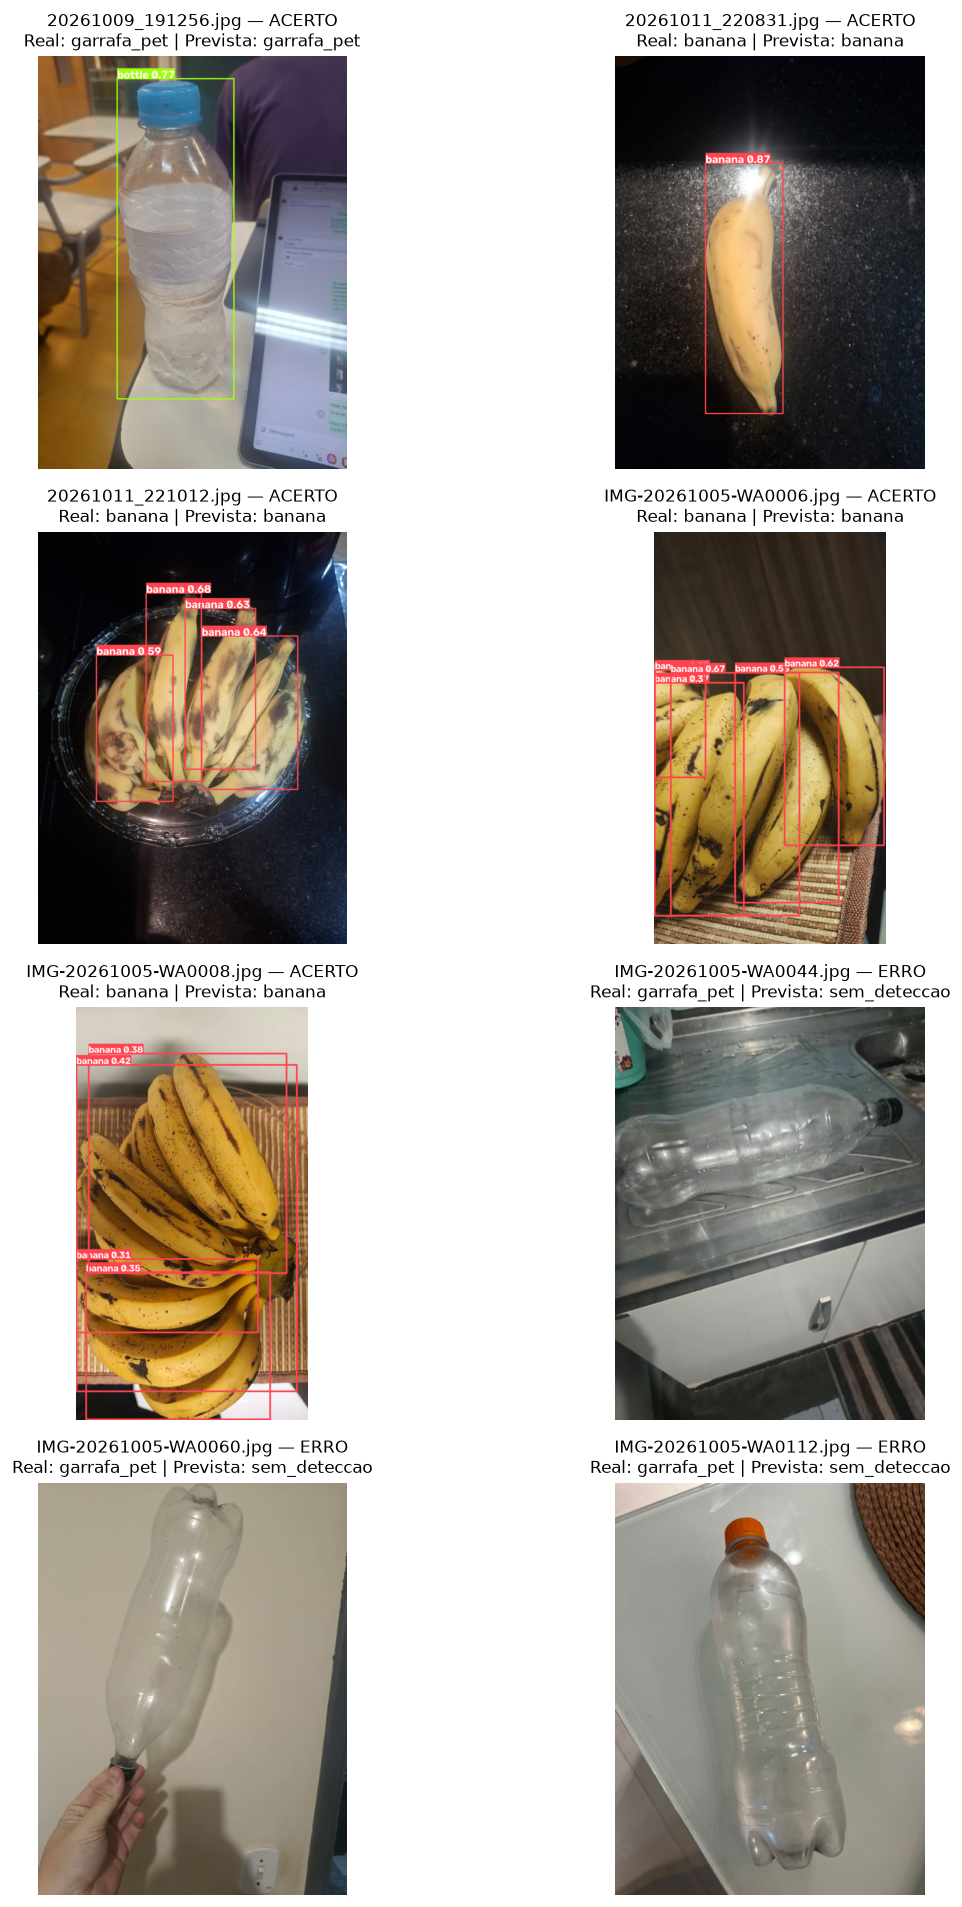

In [5]:
import matplotlib.pyplot as plt

fig, eixos = plt.subplots(4, 2, figsize=(12, 16))
for eixo, imagem, linha in zip(eixos.flat, imagens_processadas, linhas):
    eixo.imshow(imagem)
    estado = 'ACERTO' if linha['acertou'] else 'ERRO'
    eixo.set_title(f"{linha['arquivo']} — {estado}\nReal: {linha['classe_real']} | Prevista: {linha['predicao_yolo_padrao']}", fontsize=10)
    eixo.axis('off')
fig.tight_layout()
fig.savefig(FIG_DIR / 'galeria_teste.png', dpi=120, bbox_inches='tight')
plt.show()


## 6. Salvar resultados e separar a execução original da reprodução

Os tempos desta reprodução pertencem ao ambiente registrado acima. A execução original de Elton acertou 5/8 fotos e registrou aproximadamente 937,41 ms por foto em CPU. Preservamos esse registro sem substituir seu tempo pelo desta máquina.

Uma repetição das mesmas fotos verifica a implementação, mas não representa um novo conjunto independente de teste nem aumenta a amostra de oito imagens.


In [6]:
import json

resumo_padrao = {'modelo': 'YOLOv5s padrão pré-treinada no COCO',
                 'regra_avaliacao': 'maior confiança >= 0.25 entre banana e bottle; sem detecção é erro',
                 'imagens_teste': len(predicoes), 'acertos': int(predicoes['acertou'].sum()),
                 'acuracia_por_imagem': float(predicoes['acertou'].mean()),
                 'erro_por_imagem': float(1 - predicoes['acertou'].mean()),
                 'tempo_medio_inferencia_ms': float(predicoes['tempo_inferencia_ms'].mean()),
                 'escopo_tempo': 'AutoShape sobre o caminho da foto: leitura/preparação, modelo e NMS; fora da medição: carregar pesos, aquecimento, conversão em tabela, render e salvar.',
                 'limite_confianca': modelo.conf, 'iou_nms': modelo.iou,
                 'treinamento_nesta_base': False, 'pesos': 'yolov5s COCO', 'ambiente': ambiente}
predicoes.to_csv(OUTPUT_DIR / 'predicoes_yolo_padrao.csv', index=False)
caixas_df.to_csv(OUTPUT_DIR / 'caixas_yolo_padrao.csv', index=False)
(OUTPUT_DIR / 'resultado_yolo_padrao.json').write_text(json.dumps(resumo_padrao, ensure_ascii=False, indent=2), encoding='utf-8')
(OUTPUT_DIR / 'ambiente_execucao.json').write_text(json.dumps(ambiente, ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(resumo_padrao, ensure_ascii=False, indent=2))


{
  "modelo": "YOLOv5s padrão pré-treinada no COCO",
  "regra_avaliacao": "maior confiança >= 0.25 entre banana e bottle; sem detecção é erro",
  "imagens_teste": 8,
  "acertos": 5,
  "acuracia_por_imagem": 0.625,
  "erro_por_imagem": 0.375,
  "tempo_medio_inferencia_ms": 205.92164375193533,
  "escopo_tempo": "AutoShape sobre o caminho da foto: leitura/preparação, modelo e NMS; fora da medição: carregar pesos, aquecimento, conversão em tabela, render e salvar.",
  "limite_confianca": 0.25,
  "iou_nms": 0.6,
  "treinamento_nesta_base": false,
  "pesos": "yolov5s COCO",
  "ambiente": {
    "python": "3.12.3",
    "pytorch": "2.14.1+cpu",
    "torchvision": "0.29.1+cpu",
    "ultralytics": "8.4.176",
    "sistema": "Linux",
    "dispositivo": "cpu",
    "hardware": "x86_64",
    "cpu": "Intel(R) Core(TM) 7 150U",
    "threads_cpu": 4,
    "yolo_commit": "f9578796b8a64889aa9e66dc06914d19f40d338e",
    "batch_size": 1,
    "imgsz": 640,
    "precisao_numerica": "FP32"
  }
}


## 7. Acertos e erros por foto — comparação comum

Usamos as previsões efetivas da nova YOLO customizada e da nova CNN. Não inferimos que a CNN acertou cada foto a partir de um resultado agregado.

In [7]:
referencias=json.loads(ler_arquivo_projeto('docs/resultados/base_v2/yolo_padrao/referencias_comparacao.json'))
custom=referencias['yolo_customizada'];cnn=referencias['cnn']
acertos_custom=pd.read_csv(io.BytesIO(ler_arquivo_projeto(custom['fonte_acertos'])))
predicoes_cnn=pd.read_csv(io.BytesIO(ler_arquivo_projeto(cnn['fonte_predicoes'])))
assert set(acertos_custom['Foto'])==set(predicoes['arquivo'])==set(predicoes_cnn['arquivo'])
assert all(acertos_custom.set_index('Foto').loc[r['arquivo'],'Esperado']==r['classe_real'] for r in linhas)
assert all(predicoes_cnn.set_index('arquivo').loc[r['arquivo'],'sha256_imagem']==r['sha256_imagem'] for r in linhas)
n_custom=int(acertos_custom['Acertou'].eq('Sim').sum())
n_cnn=int(predicoes_cnn['acertou'].sum())
assert n_cnn==cnn['acertos']
comparacao=pd.DataFrame([
 {'abordagem':'YOLO customizada','acertos':n_custom,'fotos':8,'acerto_percentual':n_custom/8*100,'origem':'Lucas — base v2, teste reservado'},
 {'abordagem':'YOLO padrão COCO','acertos':resumo_padrao['acertos'],'fotos':8,'acerto_percentual':resumo_padrao['acuracia_por_imagem']*100,'origem':'Elton — nova inferência na base v2'},
 {'abordagem':'CNN do zero','acertos':n_cnn,'fotos':8,'acerto_percentual':n_cnn/8*100,'origem':'Matheus — CNN reexecutada na base v2'},
])
comparacao['erro_percentual']=100-comparacao['acerto_percentual']
comparacao.to_csv(OUTPUT_DIR/'comparacao_acertos_teste.csv',index=False);display(comparacao)
por_foto=predicoes[['arquivo','classe_real','predicao_yolo_padrao','acertou']].rename(columns={'acertou':'yolo_padrao_acertou'})
por_foto=por_foto.merge(acertos_custom[['Foto','Previsto','Acertou']].rename(columns={'Foto':'arquivo','Previsto':'predicao_yolo_customizada','Acertou':'yolo_customizada_acertou'}),on='arquivo',validate='one_to_one')
por_foto=por_foto.merge(predicoes_cnn[['arquivo','classe_real','predicao_cnn','acertou']].rename(columns={'classe_real':'classe_real_cnn','acertou':'cnn_acertou'}),on='arquivo',validate='one_to_one')
assert all(por_foto['classe_real']==por_foto['classe_real_cnn'])
por_foto.to_csv(OUTPUT_DIR/'comparacao_por_foto.csv',index=False)
display(por_foto[['arquivo','classe_real','yolo_customizada_acertou','yolo_padrao_acertou','cnn_acertou']])


,abordagem,acertos,fotos,acerto_percentual,origem,erro_percentual
0,YOLO customizada,7,8,87.5,"Lucas — base v2, teste reservado",12.5
1,YOLO padrão COCO,5,8,62.5,Elton — nova inferência na base v2,37.5
2,CNN do zero,8,8,100.0,Matheus — CNN reexecutada na base v2,0.0


,arquivo,classe_real,yolo_customizada_acertou,yolo_padrao_acertou,cnn_acertou
0,20261009_191256.jpg,garrafa_pet,Sim,True,True
1,20261011_220831.jpg,banana,Sim,True,True
2,20261011_221012.jpg,banana,Sim,True,True
3,IMG-20261005-WA0006.jpg,banana,Sim,True,True
4,IMG-20261005-WA0008.jpg,banana,Sim,True,True
5,IMG-20261005-WA0044.jpg,garrafa_pet,Não,False,True
6,IMG-20261005-WA0060.jpg,garrafa_pet,Sim,False,True
7,IMG-20261005-WA0112.jpg,garrafa_pet,Sim,False,True


## 8. Métricas de detecção no teste

mAP exige comparar caixas previstas com caixas reais. A CNN retorna uma classe para a foto inteira, portanto sua acurácia não é mAP. Os valores da validação também não são os do teste.

In [8]:
metricas = custom['metricas_teste']
detecao = pd.DataFrame([{'abordagem': 'YOLO customizada — teste', 'precisao_percentual': metricas['precisao'] * 100,
                        'recall_percentual': metricas['recall'] * 100, 'mAP50_percentual': metricas['map50'] * 100,
                        'mAP50_95_percentual': metricas['map50_95'] * 100}])
detecao.to_csv(OUTPUT_DIR / 'metricas_detecao_teste.csv', index=False)
display(detecao)


,abordagem,precisao_percentual,recall_percentual,mAP50_percentual,mAP50_95_percentual
0,YOLO customizada — teste,89.28376,72.842865,78.529784,51.948636


## 9. Tempos e condições de cada implementação

As três novas execuções ocorreram na mesma CPU. Os escopos abaixo ainda diferem: resolução, lote e etapas. Não devem ser usados isoladamente para declarar um vencedor de velocidade.

In [9]:
tempos=pd.DataFrame([
 {'abordagem':'YOLO customizada','treinamento_segundos':custom['tempo_treinamento_s'],'epocas':custom['epocas_escolhidas'],'inferencia_ms_por_foto':custom['tempos']['inferencia_modelo_ms_por_foto'],'hardware':custom['ambiente']['hardware'],'entrada':'640 configurado; entradas retangulares','lote_inferencia':1,'escopo_inferencia':'Cálculo da rede no detect.py; preparo e NMS separados; sem I/O completo'},
 {'abordagem':'YOLO padrão COCO','treinamento_segundos':None,'epocas':None,'inferencia_ms_por_foto':resumo_padrao['tempo_medio_inferencia_ms'],'hardware':ambiente['cpu'],'entrada':'640 configurado; AutoShape preserva proporção','lote_inferencia':1,'escopo_inferencia':resumo_padrao['escopo_tempo']},
 {'abordagem':'CNN do zero','treinamento_segundos':cnn['tempo_treinamento_s'],'epocas':cnn['epocas'],'inferencia_ms_por_foto':cnn['tempo_inferencia_ms_por_foto'],'hardware':cnn['hardware'],'entrada':cnn['entrada'],'lote_inferencia':cnn['batch_size'],'escopo_inferencia':cnn['escopo_tempo']},
])
tempos.to_csv(OUTPUT_DIR/'comparacao_tempos_condicoes.csv',index=False);display(tempos)


,abordagem,treinamento_segundos,epocas,inferencia_ms_por_foto,hardware,entrada,lote_inferencia,escopo_inferencia
0,YOLO customizada,2567.136445,60.0,169.700000,Intel(R) Core(TM) 7 150U,640 configurado; entradas retangulares,1,Cálculo da rede no detect.py; preparo e NMS se...
1,YOLO padrão COCO,NaN,NaN,205.921644,Intel(R) Core(TM) 7 150U,640 configurado; AutoShape preserva proporção,1,AutoShape sobre o caminho da foto: leitura/pre...
2,CNN do zero,21.440830,30.0,13.420508,Intel(R) Core(TM) 7 150U,128 x 128,8,predict no conjunto de teste após aquecimento;...


## 10. Avaliação crítica

**Facilidade de integração:** YOLO padrão é a opção mais rápida para experimentar classes existentes no COCO, pois dispensa treinamento na base do cliente. A customização exige coleta, caixas, treino e validação, mas adapta as classes e localiza os objetos. A CNN em Keras tem uma arquitetura curta e serve para classificar a fotografia inteira; não entrega localização nem contagem e assume uma classe alvo por foto.

**Qualidade:** os acertos por foto usam o mesmo conjunto de teste. A YOLO pode acertar a classe e deixar uma banana sem caixa em fotos com vários objetos. A equivalência entre `bottle` e garrafa PET é uma aproximação. Oito fotos de teste são poucas para concluir superioridade geral; cenas parecidas e objetos da mesma sessão podem favorecer resultados.

**Treinamento:** os experimentos de 30 e 60 épocas são independentes e o modelo é escolhido pela validação antes do teste. A CNN usa inicialização aleatória e 30 épocas; a YOLO padrão não foi treinada neste trabalho. Os tempos de treinamento são desta execução em CPU, não os antigos da Tesla T4.

**Inferência:** a tabela descreve exatamente o que foi medido. Tempos com resolução, lote e etapas distintas não formam uma disputa controlada de velocidade. Precisão de caixas, acurácia por foto e desempenho temporal respondem a perguntas diferentes.

**Correção da base:** quatro cópias redimensionadas foram substituídas e quatorze JPEGs foram normalizados antes do manifesto, evitando a regravação automática pela YOLO. Uma dupla de fotos visualmente semelhantes foi mantida exclusivamente no treino e documentada. A correção melhora a avaliação, mas a pequena amostra e a ausência de um novo teste externo continuam sendo limitações.


**Resultados efetivos da base v2:** YOLO customizada (60 épocas): **7/8 (87,50%)**; YOLO padrão: **5/8 (62,50%)**; CNN: **8/8 (100,00%)**. No teste de detecção, a customizada obteve mAP@50 de **78,53%** e mAP@50–95 de **51,95%**.
